In [ ]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from shared import CODED_CSV, BRAND_COPY, NATIVE, LUME, INK, GRID, save

In [ ]:
PROMO = re.compile(
    r"✨|shop now|ready to switch|keeps you feeling|% off|link in|"
    r"available at|www\.|http|#ad|get yours|use code", re.I)

STOPWORDS = set(ENGLISH_STOP_WORDS) | {
    "native", "deodorant", "deo", "product", "products", "use", "used", "using",
    "get", "got", "like", "would", "really", "one", "im", "dont", "ive", "also",
    "even", "still", "much", "lume", "day", "days", "make", "makes", "made",
    "ll", "ve", "re", "does", "didnt", "doesnt", "every", "single", "just",
    "don", "doesn", "didn", "wont", "cant", "isnt", "gonna",
}


def word_set(text):
    text = re.sub(r"http\S+|www\.\S+|@\w+", " ", text.lower())
    text = re.sub(r"[^a-z\s]", " ", text)
    return {w for w in text.split() if w not in STOPWORDS and len(w) > 2}

In [ ]:
nat = pd.read_csv(CODED_CSV, parse_dates=["date"])
nat = nat[nat["brand"] == "Native"]

customer_posts = nat[~nat["review_text"].str.contains(PROMO)]
brand_lines = [l.strip() for l in open(BRAND_COPY, encoding="utf-8") if l.strip()]
len(customer_posts), len(brand_lines)

(599, 55)

In [ ]:
cust_sets = [word_set(t) for t in customer_posts["review_text"]]
brand_sets = [word_set(t) for t in brand_lines]
vocab = set().union(*cust_sets) | set().union(*brand_sets)

rows = []
for word in vocab:
    cust_pct = sum(word in s for s in cust_sets) / len(cust_sets) * 100
    brand_pct = sum(word in s for s in brand_sets) / len(brand_sets) * 100
    if cust_pct >= 2 or brand_pct >= 4:
        rows.append({"term": word, "cust_pct": cust_pct,
                     "brand_pct": brand_pct, "diff": cust_pct - brand_pct})

vg = pd.DataFrame(rows)
len(vg)

87

In [ ]:
cust_top = vg.sort_values("diff", ascending=False).head(12)
brand_top = vg.sort_values("diff").head(12)
cust_top

,term,cust_pct,brand_pct,diff
26,smell,14.691152,0.000000,14.691152
23,good,12.353923,0.000000,12.353923
81,natural,9.849750,0.000000,9.849750
19,body,12.854758,3.636364,9.218394
36,work,8.347245,0.000000,8.347245
74,tried,8.013356,0.000000,8.013356
25,smells,7.679466,0.000000,7.679466
39,works,7.011686,0.000000,7.011686
24,sweat,6.176962,0.000000,6.176962
35,people,5.676127,0.000000,5.676127


In [ ]:
brand_top

,term,cust_pct,brand_pct,diff
86,clean,1.669449,12.727273,-11.057824
3,skin,4.173623,12.727273,-8.553650
58,ingredients,1.669449,9.090909,-7.421460
30,fresh,1.335559,7.272727,-5.937168
20,citrus,0.333890,5.454545,-5.120656
4,sensitive,3.839733,5.454545,-1.614813
0,free,5.008347,5.454545,-0.446198
16,stick,3.338898,3.636364,-0.297465
72,say,2.170284,1.818182,0.352102
13,baking,2.337229,1.818182,0.519047


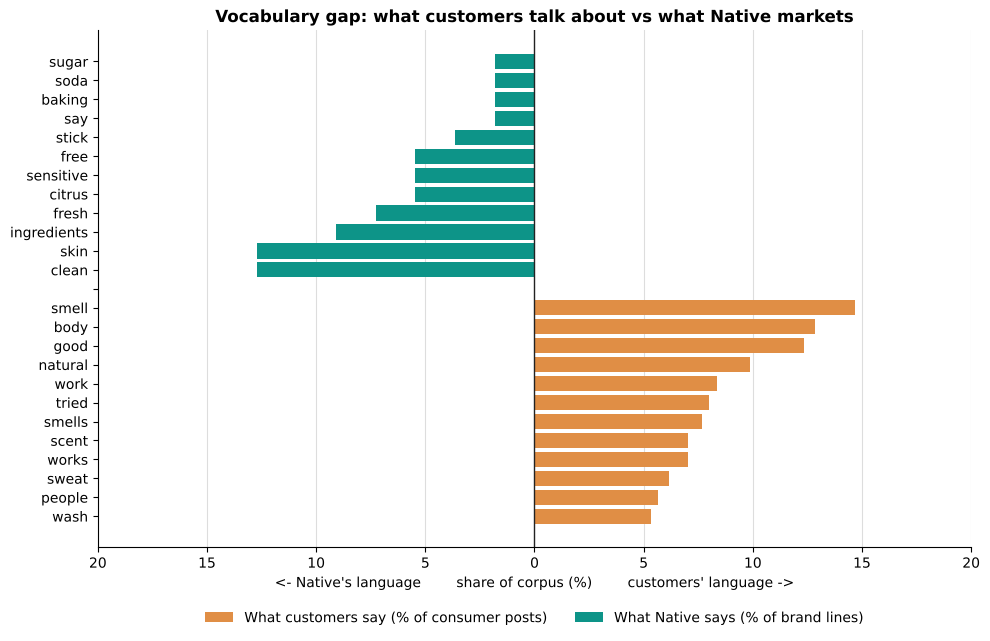

In [ ]:
c = cust_top.sort_values("cust_pct")
b = brand_top.sort_values("brand_pct", ascending=False)

labels = list(c["term"]) + [""] + list(b["term"])
cust_vals = list(c["cust_pct"]) + [0] + [0] * len(b)
brand_vals = [0] * len(c) + [0] + list(-b["brand_pct"])
y = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(y, cust_vals, color=LUME, label="What customers say (% of consumer posts)")
ax.barh(y, brand_vals, color=NATIVE, label="What Native says (% of brand lines)")
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("<- Native's language        share of corpus (%)        customers' language ->")

xmax = max(cust_top["cust_pct"].max(), brand_top["brand_pct"].max()) * 1.1
ax.set_xlim(-xmax, xmax)
ticks = ax.get_xticks()
ax.set_xticks(ticks)
ax.set_xticklabels([f"{abs(t):.0f}" for t in ticks])
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_title("Vocabulary gap: what customers talk about vs what Native markets", fontweight="bold")
save(fig, "vocabulary_gap.png")